# Importation des libraries et chargement des images

In [2]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

tf.config.set_visible_devices([], 'GPU')

#Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

#Chargement des images
observations_entrainement = pnd.read_csv('datas/fashion-mnist_train.csv')

I0000 00:00:1793198118.651106   16539 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793198123.721518   16539 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793198143.996377   16539 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1793198144.935945   16539 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


# Redimension d'une première image

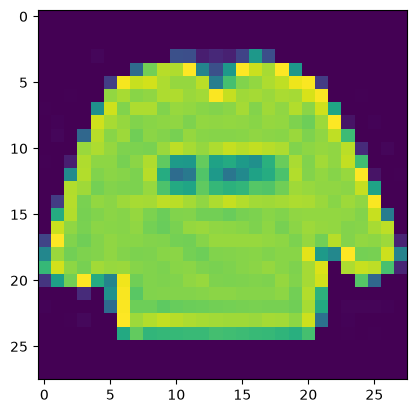

In [3]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

# Préparation des données pour l'apprentissage

In [4]:
#On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:,0]))
#Répartition des données d'entrainement en données d'apprentissage et données de validation
#80% de donnée d'apprentissage et 20% de donnée de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

# Préparation des données de validation

In [5]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], 
                                          LARGEUR_IMAGE, 
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], 
                                    LARGEUR_IMAGE, 
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

# Préparation des données de tests

In [6]:
#Preparation des données de tests
observations_test = pnd.read_csv('datas/fashion-mnist_test.csv')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], 
                        LARGEUR_IMAGE, 
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

# Configuration d'une couche de convolution

In [7]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

#1- Ajout de la couche de convolution comportant
# 32 filtres de de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
# Une image d'entrée de 28px * 28 px 
reseauNeurone1Convolution.add(Conv2D(32, 
                                     kernel_size=(3, 3), 
                                     activation='relu'))

#2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2 px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

#3- Ajout d'une fonction d'ignorance
reseauNeurone1Convolution.add(Dropout(0.2))

#5 - On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

#6 - Ajout d'un réseau de neurones composé de 128 neurones avec 
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

#7 - Ajout d'un réseau de neurones composé de 10 neurones avec une 
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

# Compilation du réseau de convolution

In [8]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

# Paramétrage de l'apprentissage

In [9]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

W0000 00:00:1793198811.008543   16539 cpu_allocator_impl.cc:82] Allocation of 150528000 exceeds 10% of free system memory.


Epoch 1/10


W0000 00:00:1793198815.420750   25346 cpu_allocator_impl.cc:82] Allocation of 22151168 exceeds 10% of free system memory.
W0000 00:00:1793198815.736177   25346 cpu_allocator_impl.cc:82] Allocation of 22151168 exceeds 10% of free system memory.


  1/188 ━━━━━━━━━━━━━━━━━━━━ 13:10 4s/step - accuracy: 0.0898 - loss: 2.3262

W0000 00:00:1793198816.217233   25346 cpu_allocator_impl.cc:82] Allocation of 22151168 exceeds 10% of free system memory.


  2/188 ━━━━━━━━━━━━━━━━━━━━ 2:07 683ms/step - accuracy: 0.2676 - loss: 2.2281

W0000 00:00:1793198816.640727   25346 cpu_allocator_impl.cc:82] Allocation of 22151168 exceeds 10% of free system memory.


188/188 ━━━━━━━━━━━━━━━━━━━━ 69s 349ms/step - accuracy: 0.8094 - loss: 0.5479 - val_accuracy: 0.8733 - val_loss: 0.3704
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 40s 211ms/step - accuracy: 0.8785 - loss: 0.3496 - val_accuracy: 0.8832 - val_loss: 0.3333
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 42s 215ms/step - accuracy: 0.8917 - loss: 0.3076 - val_accuracy: 0.8888 - val_loss: 0.3144
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 37s 195ms/step - accuracy: 0.9003 - loss: 0.2798 - val_accuracy: 0.8968 - val_loss: 0.2911
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 51s 250ms/step - accuracy: 0.9060 - loss: 0.2591 - val_accuracy: 0.9012 - val_loss: 0.2762
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 90s 291ms/step - accuracy: 0.9129 - loss: 0.2427 - val_accuracy: 0.9018 - val_loss: 0.2715
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 71s 230ms/step - accuracy: 0.9164 - loss: 0.2291 - val_accuracy: 0.9014 - val_loss: 0.2705
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 96s 306ms/step - accuracy: 0.9216 - loss: 0.2171 - val

# Évaluation de précision de l'apprentissage

In [10]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.23623208701610565
Précision: 0.9153000116348267


# Affichage graphique des courbes de précision et d'erreur après chaque epoch

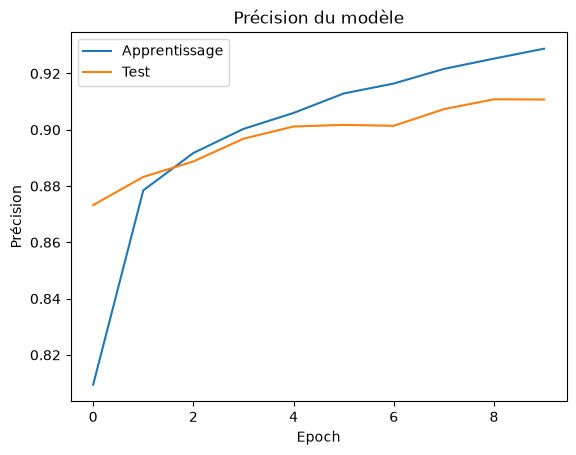

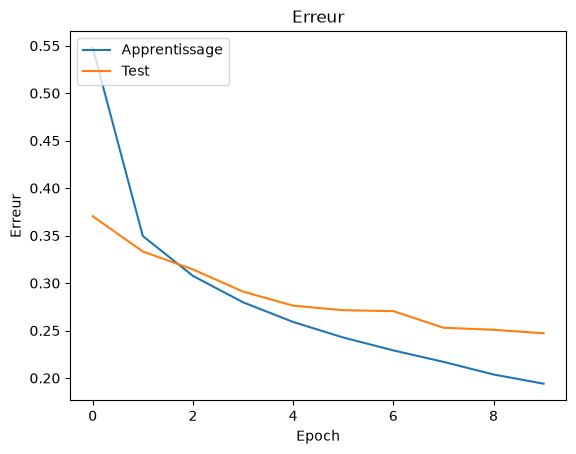

In [11]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Précision du modèle')
plt.ylabel('Précision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()
# Plot training & validation loss values
plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc='upper left')
plt.show()

# Augmentation du nombre de données à partir des images existantes

In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

# Apprentissage à partir des nouvelles données supplémentaires

In [13]:
nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50


I0000 00:00:1793199662.957036   16539 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 111s 585ms/step - accuracy: 0.8253 - loss: 0.4657 - val_accuracy: 0.8476 - val_loss: 0.4146
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 1:28 476ms/step - accuracy: 0.8320 - loss: 0.4653

/home/tv/Documents/420-5G4/ai/ateliers/420-5G4-ML/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 15s 76ms/step - accuracy: 0.8320 - loss: 0.4653 - val_accuracy: 0.8430 - val_loss: 0.4149
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 149s 701ms/step - accuracy: 0.8483 - loss: 0.4052 - val_accuracy: 0.8558 - val_loss: 0.3871
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 13s 68ms/step - accuracy: 0.8672 - loss: 0.3708 - val_accuracy: 0.8550 - val_loss: 0.3878
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 82s 437ms/step - accuracy: 0.8544 - loss: 0.3869 - val_accuracy: 0.8606 - val_loss: 0.3704
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8281 - loss: 0.3826 - val_accuracy: 0.8602 - val_loss: 0.3778
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 142s 464ms/step - accuracy: 0.8606 - loss: 0.3726 - val_accuracy: 0.8674 - val_loss: 0.3651
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.8711 - loss: 0.3596 - val_accuracy: 0.8639 - val_loss: 0.3687
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 82s 435ms/step - accuracy: 0.8657 - loss: 0.3641 - val_acc

# Sauvegarde du modèle d'apprentissage

In [15]:
#Sauvegarde du modèle
# Serialisation du modèle 
model_json = reseauNeurone1Convolution.to_json() 
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
# Serialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !
